In [2]:
import pandas as pd
  
df=pd.read_csv('C:/Users/HP/Documents/Data_Science/01-python-intro/iris_dataset.csv')
df.head(5)

,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
print(df.shape)

(150, 5)


In [4]:
print(df.columns.to_list())

['sepal_length_cm', 'sepal_width_cm', 'petal_length_cm', 'petal_width_cm', 'species']


In [5]:
print(df.dtypes)

sepal_length_cm    float64
sepal_width_cm     float64
petal_length_cm    float64
petal_width_cm     float64
species                str
dtype: object


In [6]:
df['species'].value_counts()

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

#2 Línea: secuencia de observaciones
Grafica con una línea la variable `sepal_length_cm` de las primeras 30 observaciones. Usa el índice de la fila como eje X. Agrega título y etiquetas a ambos ejes. Explica en una frase qué representa el orden en este caso.

(30, 5)

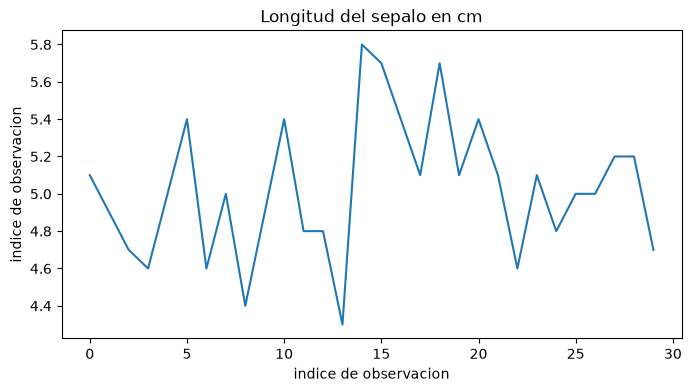

In [7]:
import matplotlib.pyplot as plt
subconjunto=df.loc[0:29,:]

plt.figure(figsize=(8,4))
plt.plot(subconjunto.index,subconjunto['sepal_length_cm'])
plt.title('Longitud del sepalo en cm')
plt.xlabel('indice de observacion')
plt.ylabel('indice de observacion')
subconjunto.shape


3. Línea: personalización
Repite el gráfico anterior usando marcador circular, línea discontinua y un color diferente. Ajusta el tamaño de la figura y agrega una cuadrícula suave.

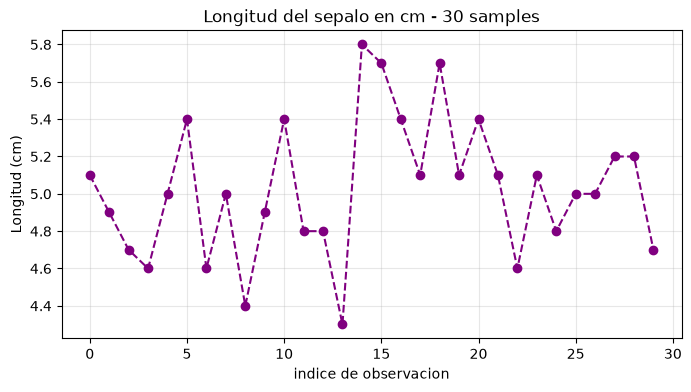

In [8]:
subconjunto=df.loc[0:29,:]

plt.figure(figsize=(8,4))
plt.plot(
    subconjunto.index,
    subconjunto['sepal_length_cm'],
    marker='o',
    linestyle='--',
    color='purple'
)

plt.title('Longitud del sepalo en cm - 30 samples')
plt.xlabel('indice de observacion')
plt.ylabel('Longitud (cm)')
plt.grid(alpha=0.3)
plt.show()

4. Barras: promedio por especie
Calcula el promedio de `sepal_length_cm` para cada `species` y represéntalo con un gráfico de barras verticales. Incluye etiquetas de ejes y título.

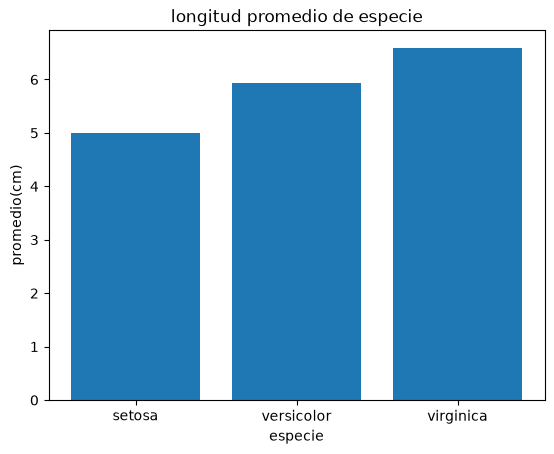

In [9]:
promedio_sepal_length=df.groupby('species')['sepal_length_cm'].mean()
plt.bar(promedio_sepal_length.index,promedio_sepal_length.values)
plt.title('longitud promedio de especie')
plt.xlabel('especie')
plt.ylabel('promedio(cm)')
plt.show()

5. Barras horizontales
Calcula el promedio de `petal_length_cm` por especie y crea un gráfico de barras horizontales. Ordena las especies de menor a mayor promedio antes de graficar.

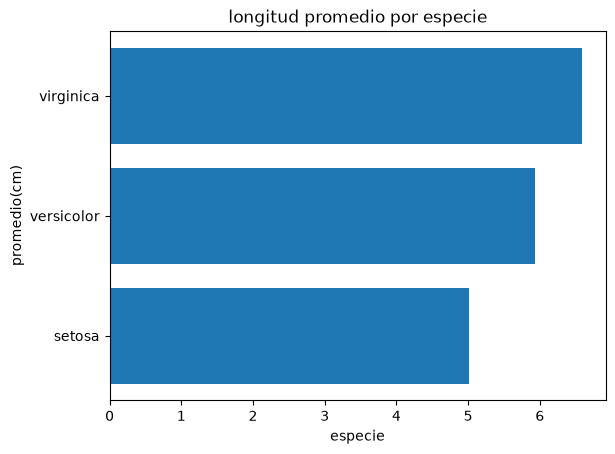

In [10]:
promedio_petal_length=df.groupby('species')['sepal_length_cm'].mean()

plt.barh(promedio_petal_length.index,promedio_petal_length.values)
plt.title('longitud promedio por especie')
plt.xlabel('especie')
plt.ylabel('promedio(cm)')
plt.show()

6. Pastel: composición del dataset
Calcula cuántas observaciones existen por especie y represéntalas con un gráfico de pastel. Muestra los porcentajes con un decimal. ¿Qué conclusión obtienes sobre el balance del dataset?

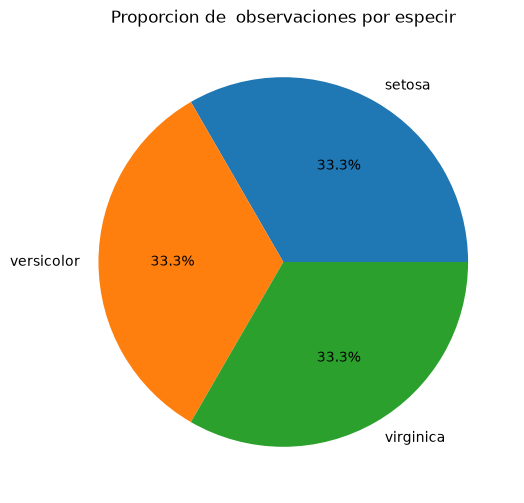

In [11]:
counts=df['species'].value_counts()
counts

plt.figure(figsize=(6,6))
plt.pie(counts.values,labels=counts.index,autopct='%1.1f%%')
plt.title('Proporcion de  observaciones por especir')
plt.show()

7. Dispersión: sépalo
Crea un scatter plot entre `sepal_length_cm` y `sepal_width_cm`. Agrega título y etiquetas. Describe si visualmente parece existir una relación clara entre ambas variables.

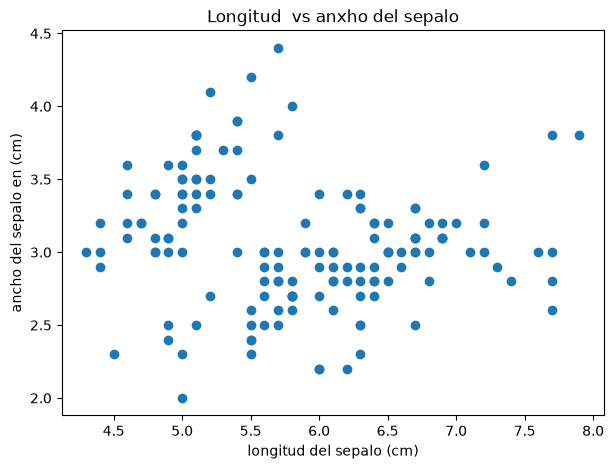

In [12]:
plt.figure(figsize=(7,5))
plt.scatter(df['sepal_length_cm'], df['sepal_width_cm'])
plt.title('Longitud  vs anxho del sepalo')
plt.xlabel('longitud del sepalo (cm)')
plt.ylabel('ancho del sepalo en (cm)')
plt.show()

8. Dispersión por especie
Crea un gráfico de dispersión entre `petal_length_cm` y `petal_width_cm`, diferenciando cada especie con una serie distinta y una leyenda. No uses Seaborn.

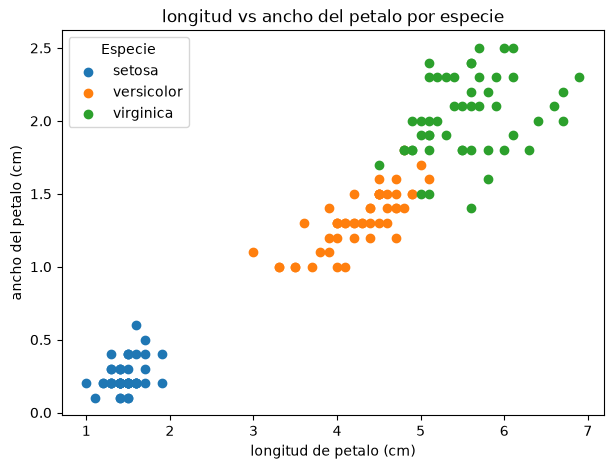

In [13]:
plt.figure(figsize=(7,5))
for species, group in df.groupby('species'):
    plt.scatter(
        group['petal_length_cm'],
        group['petal_width_cm'],
        label=species,
    )
plt.title('longitud vs ancho del petalo por especie')
plt.xlabel('longitud de petalo (cm)')
plt.ylabel('ancho del petalo (cm)')
plt.legend(title='Especie')

plt.show()

9.Histograma:longitud del sépalo
Crea un histograma de `sepal_length_cm` con 10 bins, borde visible y etiquetas. Describe dónde se concentra la mayor parte de las observaciones.

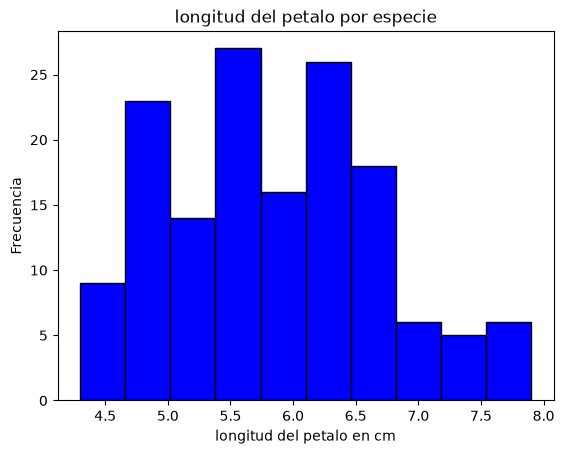

In [14]:
plt.hist(
    df["sepal_length_cm"],
    bins=10,
    edgecolor="black",
    color="blue",
)

plt.xlabel("longitud del petalo en cm")
plt.ylabel("Frecuencia")
plt.title("longitud del petalo por especie")

plt.show()

10. Histograma y bins
Crea dos histogramas de `petal_length_cm`: uno con 5 bins y otro con 20 bins. Colócalos lado a lado usando subplots.

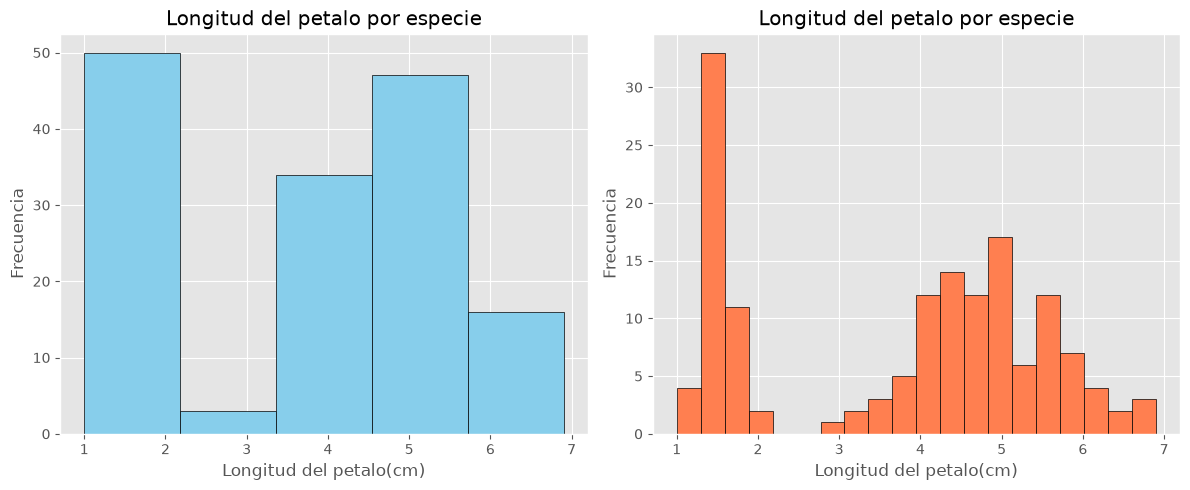

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].hist(df["petal_length_cm"], bins=5, edgecolor="black", color="skyblue")
axes[0].set_title("Longitud del petalo por especie")
axes[0].set_xlabel("Longitud del petalo(cm)")
axes[0].set_ylabel("Frecuencia")

axes[1].hist(
    df["petal_length_cm"], bins=20, edgecolor="black", color="coral"
)
axes[1].set_title("Longitud del petalo por especie")
axes[1].set_xlabel("Longitud del petalo(cm)")
axes[1].set_ylabel("Frecuencia")

plt.tight_layout()
plt.show()

11. Boxplot por especie
 
Construye un boxplot de `sepal_length_cm` separado por especie. Etiqueta cada caja con el nombre de su especie y compara visualmente las medianas.

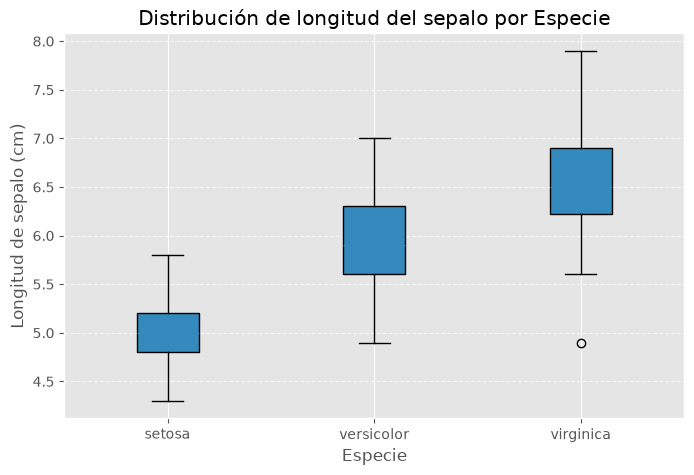

In [22]:
especies = df["species"].unique()
datos_especie = [
    df[df["species"] == sp]["sepal_length_cm"] for sp in especies
]

plt.figure(figsize=(8, 5))
plt.boxplot(
    datos_especie,
    tick_labels=especies,
    patch_artist=True,
)

plt.title("Distribución de longitud del sepalo por Especie")
plt.xlabel("Especie")
plt.ylabel("Longitud de sepalo (cm)")
plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.show()

12. Boxplot de variables numéricas
Crea un solo boxplot que compare las cuatro variables numéricas del dataset. Usa etiquetas cortas y legibles para cada caja. ¿Qué problema de escala observas?

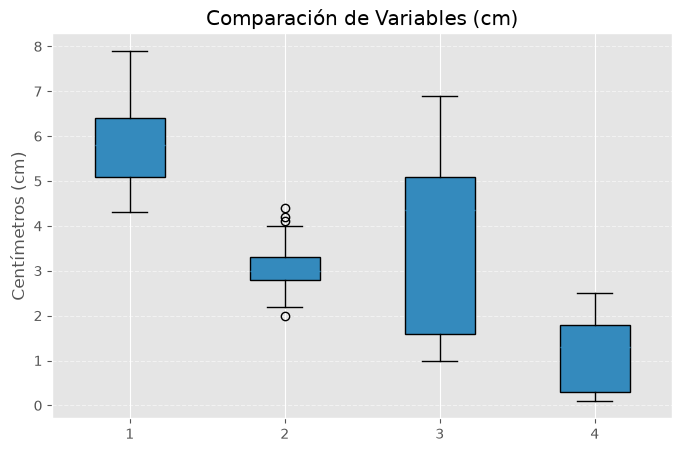

In [24]:
columnas = [
    "sepal_length_cm",
    "sepal_width_cm",
    "petal_length_cm",
    "petal_width_cm",
]
etiquetas = ["Longitud sepalo.", "ancho de sepalo", "longitud de Petalo", "ancho de Petalo"]

plt.figure(figsize=(8, 5))

plt.boxplot(
    [df[col] for col in columnas], label=etiquetas, patch_artist=True
)

plt.title("Comparación de Variables (cm)")
plt.ylabel("Centímetros (cm)")
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.show()

13. Subplots 1x2 
Crea una figura con dos subplots: a la izquierda un scatter de `sepal_length_cm` vs. `sepal_width_cm`; a la derecha un histograma de `sepal_length_cm`. Agrega un título independiente a cada panel. 

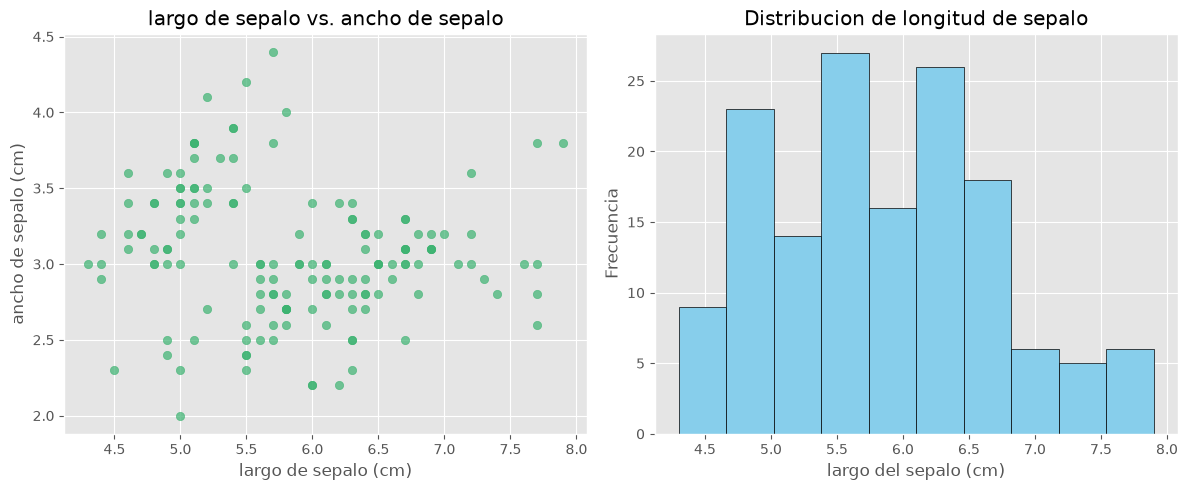

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(
    df["sepal_length_cm"],
    df["sepal_width_cm"],
    color="mediumseagreen",
    alpha=0.7,
)
axes[0].set_title("largo de sepalo vs. ancho de sepalo")
axes[0].set_xlabel("largo de sepalo (cm)")
axes[0].set_ylabel("ancho de sepalo (cm)")

axes[1].hist(df["sepal_length_cm"], bins=10, edgecolor="black", color="skyblue")
axes[1].set_title("largo de sepalo de especies")
axes[1].set_xlabel("largo del sepalo (cm)")
axes[1].set_ylabel("Frecuencia")

plt.tight_layout()

plt.show()

15.
 
Leyendas
 
y
 
etiquetas
 
Crea nuevamente el scatter de `petal_length_cm` vs. `petal_width_cm` por especie. Esta vez agrega 
título general, etiquetas de ejes, leyenda y cuadrícula. La figura debe ser autoexplicativa sin leer el 
código.

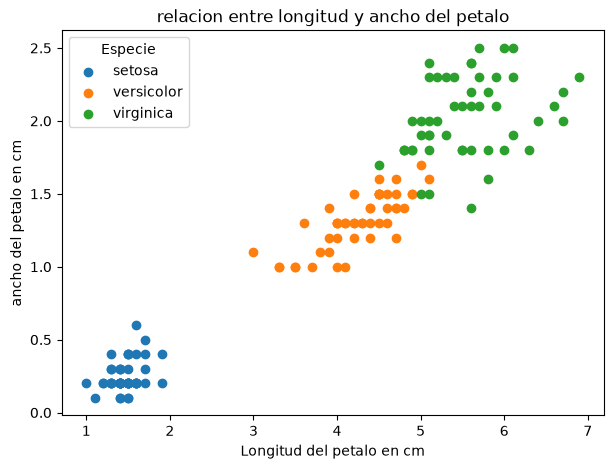

In [15]:
fig, ax=plt.subplots(figsize=(7,5))
for species, group in df.groupby('species'):
    plt.scatter(
        group['petal_length_cm'],
        group['petal_width_cm'],
        label=species,
    )

ax.set_title('relacion entre longitud y ancho del petalo')
ax.set_xlabel('Longitud del petalo en cm')
ax.set_ylabel('ancho del petalo en cm')
ax.legend(title='Especie')


16. Estilos. Aplica temporalmente el estilo `ggplot` a un gráfico de barras con el promedio de `sepal_width_cm` por 
especie. Al terminar, restaura el estilo `default` para no afectar gráficos posteriores.

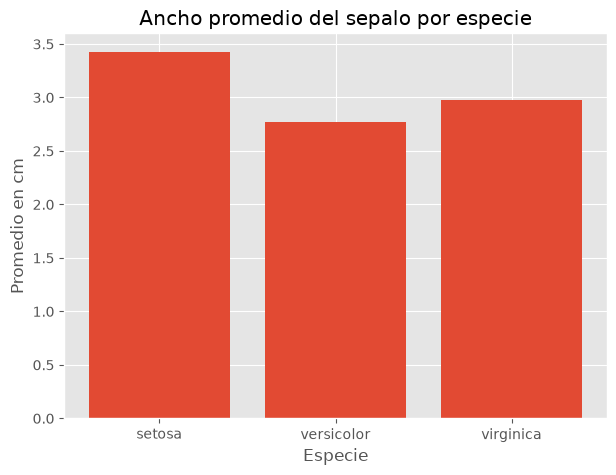

In [16]:
mean_sepal_width=df.groupby('species')['sepal_width_cm'].mean()

plt.style.use('ggplot')
fix,ax=plt.subplots(figsize=(7,5))
ax.bar(mean_sepal_width.index, mean_sepal_width.values)
ax.set_title('Ancho promedio del sepalo por especie')
ax.set_xlabel('Especie')
ax.set_ylabel('Promedio en cm')
plt.show()

17.POO: Figure y Axes
Usando exclusivamente el enfoque orientado a objetos (`fig, ax = plt.subplots()`), crea un gráfico de 
barras con el promedio de `petal_width_cm` por especie. Configura título y etiquetas con métodos de `Axes`. 

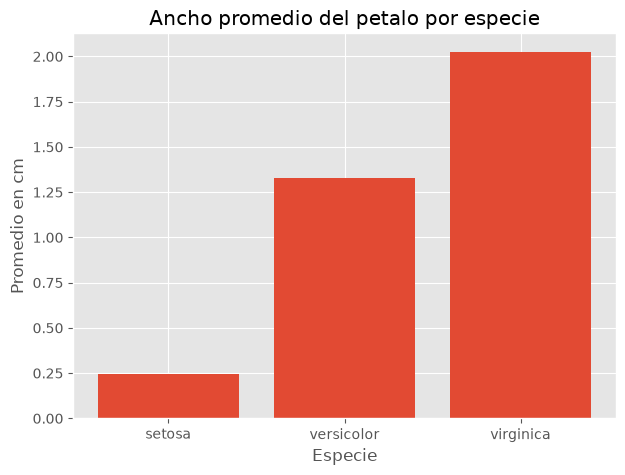

In [17]:
mean_petal_width=df.groupby('species')['petal_width_cm'].mean()

#plt.style.use('ggplot')
fix,ax=plt.subplots(figsize=(7,5))
ax.bar(mean_petal_width.index, mean_petal_width.values)
ax.set_title('Ancho promedio del petalo por especie')
ax.set_xlabel('Especie')
ax.set_ylabel('Promedio en cm')
plt.show()

18. POO: múltiples Axes. Con `fig, axes = plt.subplots(1, 3)`, crea un boxplot independiente de `petal_length_cm` para cada 
especie. Cada panel debe tener el nombre de la especie como título y la misma escala en Y. 

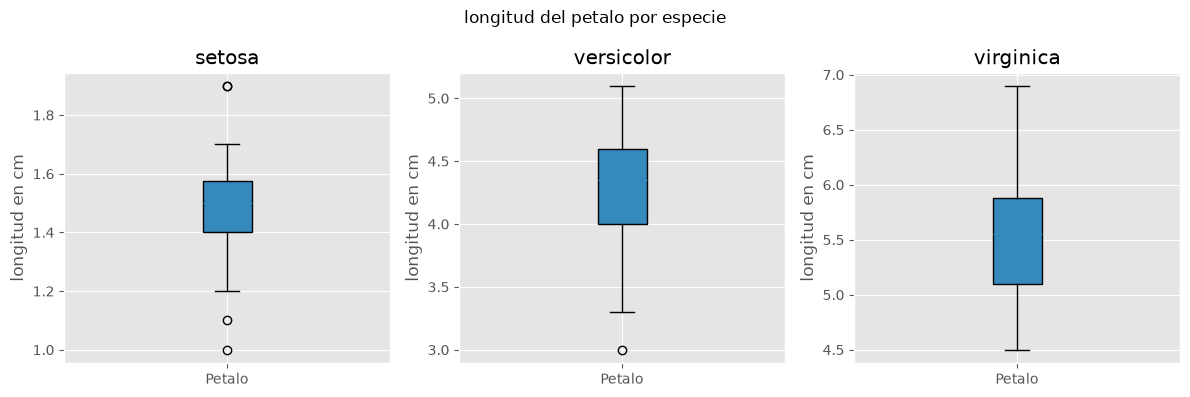

In [18]:
fig, axes=plt.subplots(1,3, figsize=(12,4))
for ax, (species, group) in zip(axes, df.groupby('species')):
    petal_length_cm=group['petal_length_cm']
    ax.boxplot(petal_length_cm,patch_artist=True)
    ax.set_title(species)
    ax.set_xticks([1])
    ax.set_xticklabels(['Petalo'])
    ax.set_ylabel('longitud en cm')
fig.suptitle('longitud del petalo por especie')
fig.tight_layout()
plt.show()

19. Gráfico principal + gráfico insertado
Usa `Figure.add_axes()` para crear un scatter principal de `petal_length_cm` vs. `petal_width_cm` y un eje pequeño insertado que muestre un histograma de `petal_length_cm`. Añade títulos apropiados.

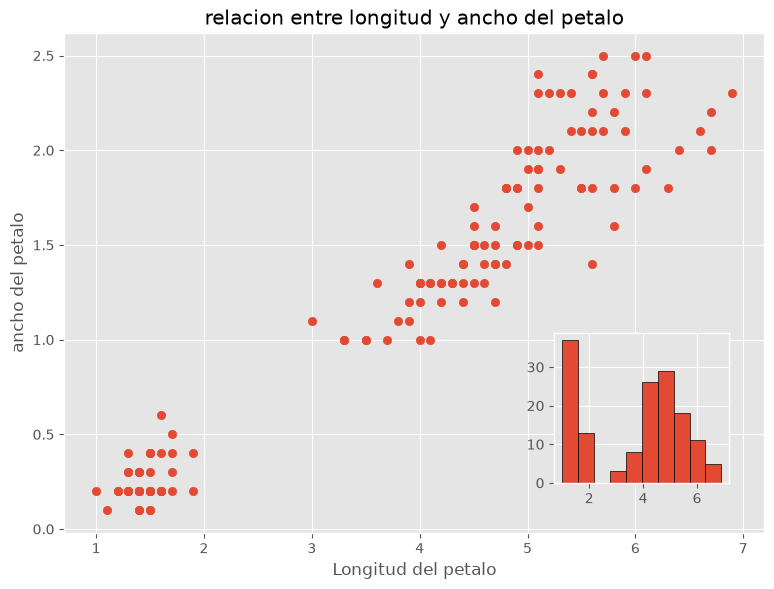

In [19]:
fig=plt.figure(figsize=(7,5))
ax_principal=fig.add_axes([0,0,1,1])
ax_secundario=fig.add_axes([0.7,0.1,0.25,0.3])

ax_principal.scatter(df['petal_length_cm'], df['petal_width_cm'])
ax_principal.set_title('relacion entre longitud y ancho del petalo')
ax_principal.set_xlabel('Longitud del petalo')
ax_principal.set_ylabel('ancho del petalo')

ax_secundario.hist(df['petal_length_cm'], bins=10,edgecolor='black')
ax_secundario.set_title=('Distribucion')

plt.show()

20.Mini dashboard final
 
Construye una figura 2x2 que resuma el dataset con cuatro visualizaciones diferentes: (1) barras del promedio de longitud de sépalo por especie, (2) scatter de longitud vs. ancho de pétalo por especie, (3) histograma de ancho de sépalo y (4) boxplot de longitud de pétalo por especie. Usa POO, títulos claros, leyendas cuando correspondan y `tight_layout()`.

In [20]:
fig, axes=plt.subplots(2,2, figsize=(12,9))
mean_sepal=df.groupby('species')['sepal_length_cm'].mean()
axes[0,0].bar(mean_sepal.index, mean_sepal.values)
axes[0,0].set_ylabel('promedio en cm')

for species, group in df.groupby('species'):
    axes[0,1].scatter(
        group['petal_length_cm'],
        group['petal_width_cm'],
        label=species
    )
axes[0,1].set_title('Longitud vs ancho del petalo')
axes[0,1].set_xlabel('longitud en cm')
axes[0,1].set_ylabel('ancho en cm')
axes[0,1].legend(title='especie')

axes[1,0]_principal.scatter(df['petal_length_cm'], df['petal_width_cm'])
ax_principal.set_title('relacion entre longitud y ancho del petalo')
ax_principal.set_xlabel('Longitud del petalo')
ax_principal.set_ylabel('ancho del petalo')

species_unicas=list(df['species'].unique())
print(species_unicas)
longitudes_petalo=[df[df['species']==species]['petal_length_cm'] for species in species_unicas]

axes[1,1].boxplot(longitudes_petalo, label=
['petal_length_cm']petal_length_cm,patch_artist=True)
axes[1,1].set_title('Longitud del petalo por especie')
axes[1,1].set_ylabel('cm')
fig.subtitle('Mini dashboards dataset IRIS')

plt.show()

SyntaxError: invalid syntax (499950802.py, line 17)